In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "hourly_transformed.parquet"

eda_data = pd.read_parquet(DATA_PATH)

print("EDA dataset loaded from:", DATA_PATH)
print("Dataset shape:", eda_data.shape)
print("Dataset columns:", eda_data.dtypes)
eda_data.sample(5)

EDA dataset loaded from: /home/global-rex/Documents/bikeshare-intelligence/data/processed/hourly_transformed.parquet
Dataset shape: (17379, 32)
Dataset columns: instant                   int64
dteday           datetime64[us]
season                    int64
yr                        int64
mnth                      int64
hr                        int64
holiday                   int64
weekday                   int64
workingday                int64
weathersit                int64
temp                    float64
atemp                   float64
hum                     float64
windspeed               float64
casual                    int64
registered                int64
cnt                       int64
timestamp        datetime64[us]
year                      int32
month                     int32
day                       int32
hour                      int32
day_of_week               int32
day_name                    str
quarter                   int32
isweekend                 int64
season_

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,day_of_week,day_name,quarter,isweekend,season_name,weather_name,temp_c,atemp_c,humidity_pct,windspeed_kmh
15941,15942,2012-11-01,4,1,11,22,0,4,1,1,...,3,Thursday,4,0,Winter,Clear,14.04,17.425,57.0,11.0014
3817,3818,2011-06-12,2,0,6,23,0,0,0,1,...,6,Sunday,2,1,Summer,Clear,24.96,29.545,78.0,12.9980
3020,3021,2011-05-10,2,0,5,18,0,2,1,1,...,1,Tuesday,2,0,Summer,Clear,24.96,31.060,29.0,8.9981
5251,5252,2011-08-11,3,0,8,17,0,4,1,1,...,3,Thursday,3,0,Fall,Clear,31.20,34.850,29.0,16.9979
3649,3650,2011-06-05,2,0,6,23,0,0,0,1,...,6,Sunday,2,1,Summer,Clear,24.18,29.545,78.0,8.9981


### 4.2 Hourly Demand Analysis

Analyze average rental demand across the 24 hours of the day.

This analysis will identify peak and off-peak periods
and help management understand daily demand patterns.

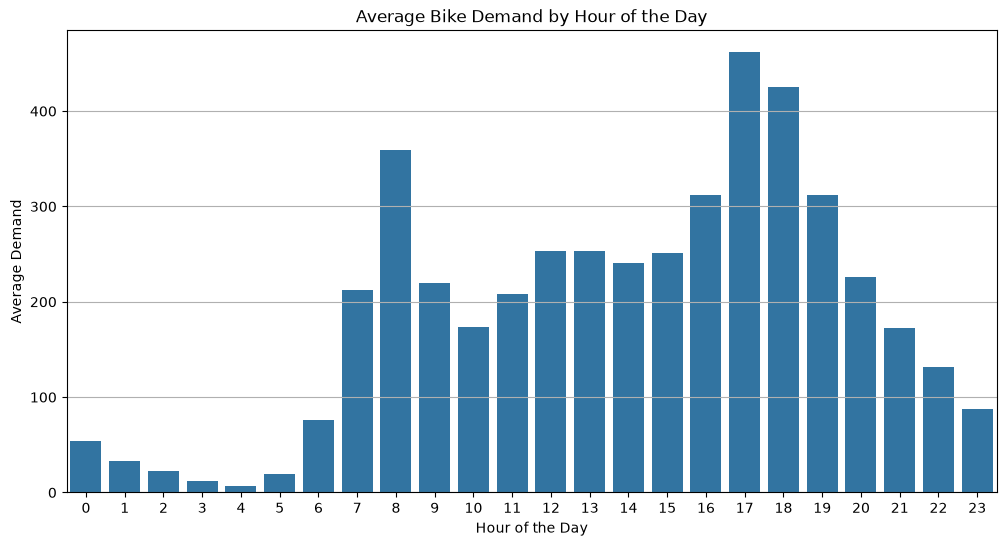

In [7]:
hourly_demand = (eda_data.groupby('hour')['cnt'].mean().reset_index().sort_values(by='hour'))
hourly_demand_columns = ['hour', 'average_demand']

#Plotting the average demand by hour
plt.figure(figsize=(12, 6))
sns.barplot(x='hour', y='cnt', data=hourly_demand)
plt.title('Average Bike Demand by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Demand')
plt.xticks(range(0, 24))
plt.grid(axis='y')
plt.show()

## Hourly Demand Analysis

1. Peak demand: 17:00
2. Lowest demand: 4:00
3. Observed demand pattern: Highest demand on morning and evening time period
4. Possible explanation: Commute Hours cause high demand
5. Business implication: Bike rentals reach peak at daily commute hours with regular office hours having highest rentals

### 4.3 Working-Day vs Weekend Demand

Compare hourly rental demand between working days and weekends
to identify differences in customer activity patterns.

This analysis will help determine whether demand peaks are
primarily associated with commuting patterns or other activities.

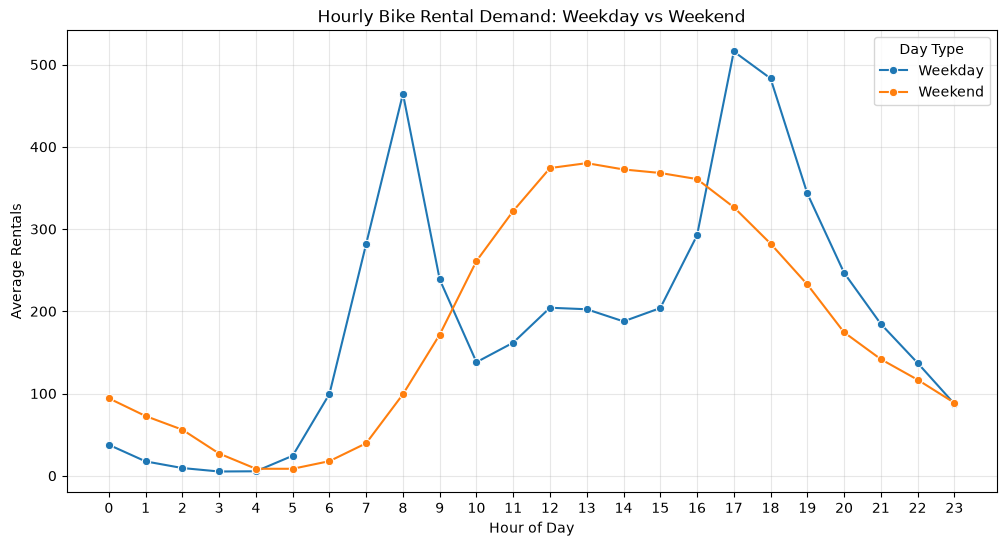

In [11]:
daytype_demand = (eda_data.groupby(['isweekend', 'hour'])['cnt'].mean().reset_index().sort_values(by='hour'))

daytype_demand['daytype'] = daytype_demand['isweekend'].map({0: 'Weekday', 1: 'Weekend'})

#Plotting the average demand by hour and day type
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daytype_demand,
    x='hour',
    y='cnt',
    hue='daytype',
    marker='o'
)

plt.title('Hourly Bike Rental Demand: Weekday vs Weekend')
plt.xlabel('Hour of Day')
plt.ylabel('Average Rentals')
plt.xticks(range(24))
plt.legend(title='Day Type')
plt.grid(True, alpha=0.3)

plt.show()

### 4.4 Monthly Demand Analysis

Analyze average bike rental demand across the 12 months
to identify recurring seasonal variations in customer activity.

This analysis will help management understand how demand
changes throughout the year.

In [14]:
monthly_demand = (
    eda_data.groupby('month')['cnt']
    .mean()
    .reset_index()
)

monthly_demand.columns = ['month', 'average_rentals']

monthly_demand

,month,average_rentals
0,1,94.424773
1,2,112.865026
2,3,155.410726
3,4,187.260960
4,5,222.907258
5,6,240.515278
6,7,231.819892
7,8,238.097627
8,9,240.773138
9,10,222.158511


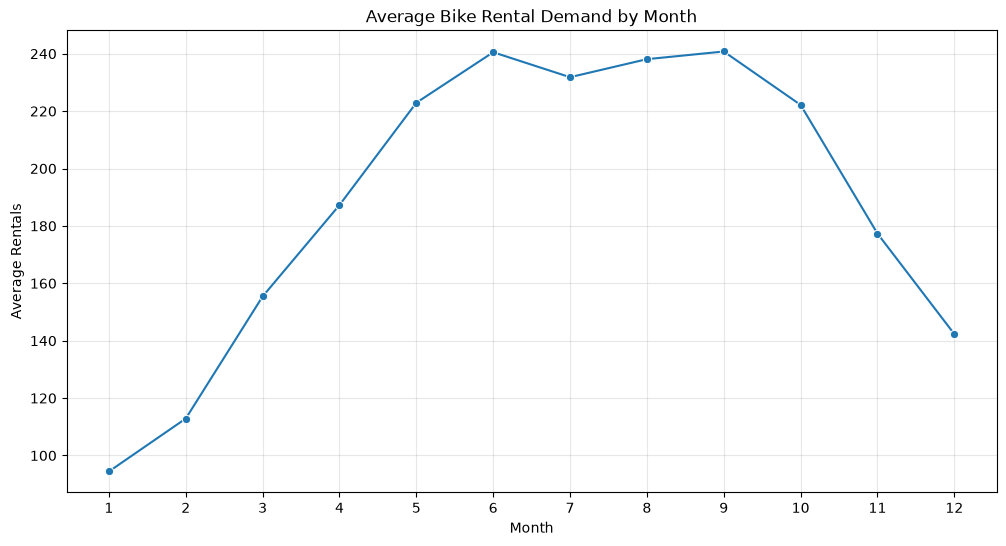

In [15]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_demand,
    x='month',
    y='average_rentals',
    marker='o'
)

plt.title('Average Bike Rental Demand by Month')
plt.xlabel('Month')
plt.ylabel('Average Rentals')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

plt.show()

### 4.5 Seasonal Demand Analysis

Analyze average rental demand across the four seasons
to identify broader seasonal variations.

This analysis will help management understand
which seasons experience the highest and lowest demand.

In [19]:
seasonal_demand = (
    eda_data.groupby('season_name')['cnt']
    .mean()
    .reindex(['Spring', 'Summer', 'Fall', 'Winter'])
    .reset_index()
)

seasonal_demand.columns = ['season', 'average_rentals']

seasonal_demand


,season,average_rentals
0,Spring,111.114569
1,Summer,208.344069
2,Fall,236.016237
3,Winter,198.868856


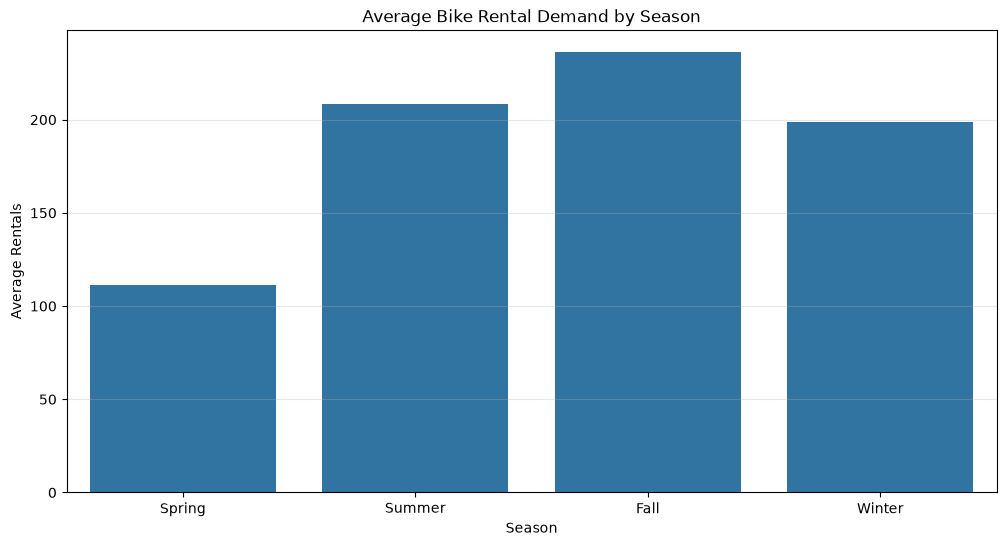

In [21]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_demand,
    x='season',
    y='average_rentals'
)

plt.title('Average Bike Rental Demand by Season')
plt.xlabel('Season')
plt.ylabel('Average Rentals')

plt.grid(axis='y', alpha=0.3)
plt.show()

### 4.6 Weather-Based Demand Analysis

Investigate the relationship between weather conditions
and hourly bike rental demand.

Compare average rental volumes across weather categories
to understand how environmental conditions are associated
with customer activity.

In [22]:
weather_demand = (
    eda_data.groupby('weather_name')['cnt']
    .agg(['mean', 'median', 'count'])
    .reset_index()
)

weather_demand.columns = [
    'weather',
    'average_rentals',
    'median_rentals',
    'observations'
]

weather_demand

,weather,average_rentals,median_rentals,observations
0,Clear,204.869272,159.0,11413
1,Heavy Rain/Snow,74.333333,36.0,3
2,Light Rain/Snow,111.579281,63.0,1419
3,Mist/Cloudy,175.165493,133.0,4544


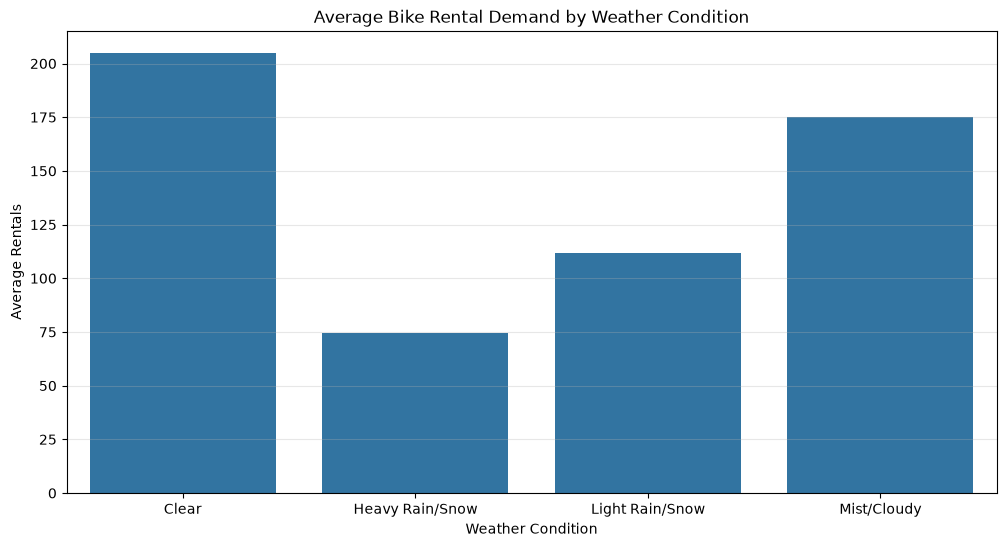

In [23]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=weather_demand,
    x='weather',
    y='average_rentals'
)
plt.title('Average Bike Rental Demand by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Rentals')
plt.grid(axis='y', alpha=0.3)
plt.show()

Bike rental demand shows a negative association with worsening weather conditions. Clear weather experiences the highest average demand (204.87 rentals/hour), followed by mist/cloudy conditions (175.17) and light rain/snow (111.58). Both mean and median demand decline across these categories. This suggests that weather conditions may influence customer willingness to use bike-sharing services. Management could incorporate weather conditions into demand planning and fleet allocation. However, heavy rain/snow observations are insufficient for reliable conclusions.

### 4.7 Customer Segment Analysis

Investigate the contribution and behaviour of casual and registered
customers to understand differences between customer segments.

This analysis will help management identify usage patterns
and potential opportunities for customer retention and conversion.

In [24]:
customer_totals = (
    pd.DataFrame({
        'Customer Type': ['Casual', 'Registered'],
        'Total Rentals': [eda_data['casual'].sum(), eda_data['registered'].sum()]
    })
)

customer_totals['percentage'] = (
    customer_totals['Total Rentals'] / customer_totals['Total Rentals'].sum() * 100
)

customer_totals

,Customer Type,Total Rentals,percentage
0,Casual,620017,18.830168
1,Registered,2672662,81.169832


Registered customers account for 81.17% of total bike rentals, while casual customers contribute 18.83%. This indicates that rental activity is predominantly driven by registered members. Management should prioritize member retention while exploring opportunities to convert frequent casual users into registered customers.

### 4.7.2 Hourly Customer Segment Analysis

Compare hourly rental patterns between casual and registered
customers to identify differences in their usage behaviour.

This analysis will help management understand whether
different customer segments have distinct demand periods.

In [25]:
customer_hourly = (
    eda_data.groupby('hour')[['casual', 'registered']]
    .mean()
    .reset_index()
)

customer_hourly

,hour,casual,registered
0,0,10.158402,43.739669
1,1,6.504144,26.871547
2,2,4.772028,18.097902
3,3,2.715925,9.011478
4,4,1.253945,5.098996
5,5,1.411437,18.478382
6,6,4.161379,71.882759
7,7,11.055021,201.009629
8,8,21.679505,337.331499
9,9,30.891334,188.418157


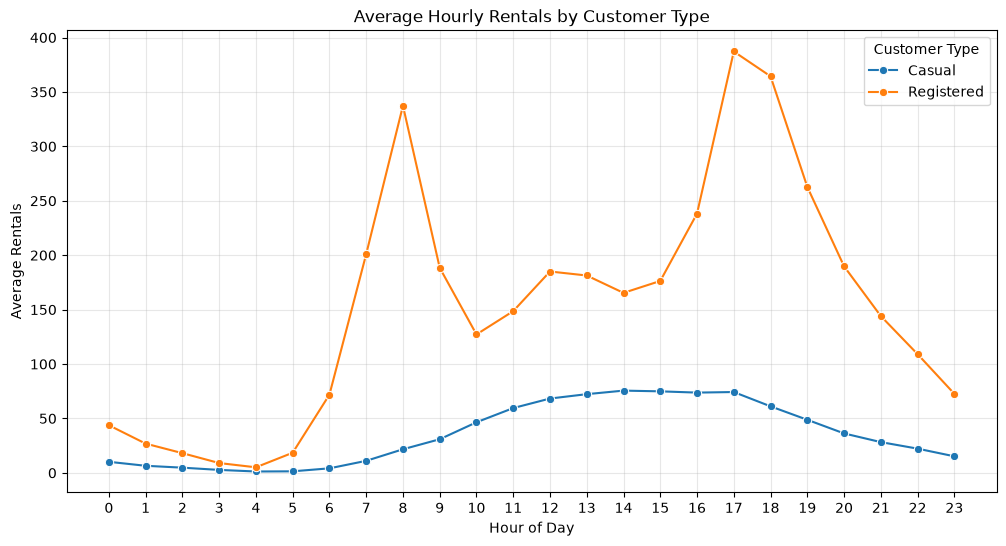

In [26]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=customer_hourly,
    x='hour',
    y='casual',
    label='Casual',
    marker='o'
)
sns.lineplot(
    data=customer_hourly,
    x='hour',
    y='registered',
    label='Registered',
    marker='o'
)
plt.title('Average Hourly Rentals by Customer Type')
plt.xlabel('Hour of Day')
plt.ylabel('Average Rentals')
plt.xticks(range(24))
plt.legend(title='Customer Type')
plt.grid(True, alpha=0.3)
plt.show()

### 4.7.3 Customer Segment Analysis: Weekday vs Weekend

Compare casual and registered customer demand across weekdays
and weekends to understand how customer segments contribute
to different daily usage patterns.

In [27]:
segment_daytype = (
    eda_data.groupby('isweekend')[['casual', 'registered']]
    .mean()
    .reset_index()
)

segment_daytype['day_type'] = segment_daytype['isweekend'].map({
    0: 'Weekday',
    1: 'Weekend'
})

segment_daytype

,isweekend,casual,registered,day_type
0,0,26.335948,165.402426,Weekday
1,1,58.710211,125.141803,Weekend


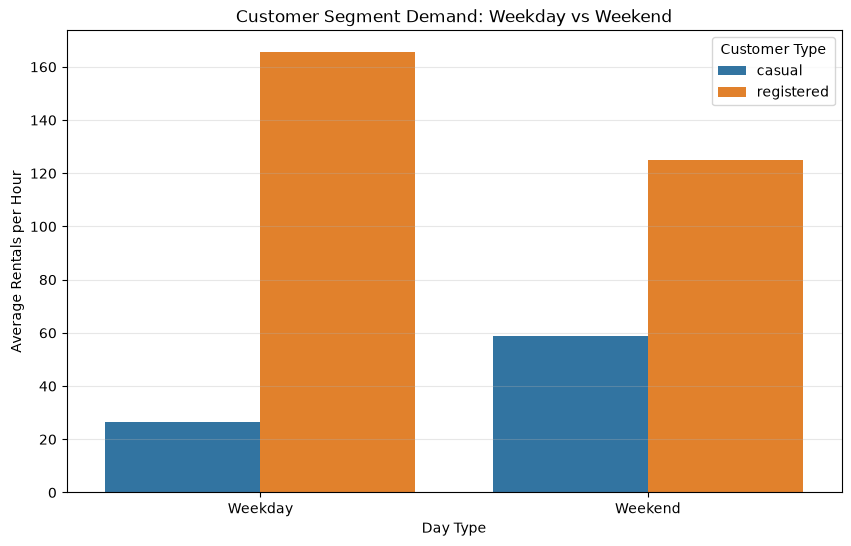

In [30]:
plt.figure(figsize=(10, 6))

segment_daytype_plot = segment_daytype.melt(
    id_vars='day_type',
    value_vars=['casual', 'registered'],
    var_name='customer_type',
    value_name='average_rentals'
)

sns.barplot(
    data=segment_daytype_plot,
    x='day_type',
    y='average_rentals',
    hue='customer_type'
)

plt.title('Customer Segment Demand: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Average Rentals per Hour')
plt.legend(title='Customer Type')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [31]:
segment_daytype_share = segment_daytype.copy()

segment_daytype_share['total_rentals'] = (
    segment_daytype_share['casual']
    + segment_daytype_share['registered']
)

segment_daytype_share['casual_pct'] = (
    segment_daytype_share['casual']
    / segment_daytype_share['total_rentals']
) * 100

segment_daytype_share['registered_pct'] = (
    segment_daytype_share['registered']
    / segment_daytype_share['total_rentals']
) * 100

segment_daytype_share[
    ['day_type', 'casual_pct', 'registered_pct']
]

,day_type,casual_pct,registered_pct
0,Weekday,13.735356,86.264644
1,Weekend,31.933407,68.066593


## 4.8 EDA Findings and Business Insights

This section consolidates the major findings from exploratory
data analysis and translates them into actionable business insights.

The findings cover hourly demand, day-type differences,
seasonal variations, weather relationships and customer behaviour.



## Summary

| Analysis | Key finding | Business implication |
|---|---|---|
| Hourly demand | Highest demand at 17:00; lowest at 04:00 | Optimize fleet availability around peak hours. |
| Weekday vs weekend | Weekdays have strong commuting-hour peaks; weekends have sustained daytime demand. | Use different operational schedules for weekdays and weekends. |
| Monthly demand | Demand rises until May and declines from September. | Incorporate monthly demand patterns into resource planning. |
| Seasonal demand | Fall has the highest average demand (236); Spring the lowest (111). | Account for seasonal differences in fleet utilization. |
| Weather | Average demand declines under less favourable weather conditions. | Incorporate weather into demand planning. |
| Customer composition | Registered customers contribute 81.17% of rentals. | Prioritize registered customer retention. |
| Customer behaviour | Casual customers account for 31.93% of weekend rentals versus 13.74% on weekdays. | Investigate weekend-focused customer acquisition and membership conversion. |